In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")
%matplotlib inline

In [3]:
df = pd.read_csv("Titanic-Dataset.csv")      # Titanic (Kaggle train.csv) - keep it in the same folder as this notebook
print("Rows:", df.shape[0], " Columns:", df.shape[1])
df.head()

Rows: 891  Columns: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
print("\nDataset Columns")
print(df.columns.tolist())
print("\nDataset Information")
df.info()
print("\nMissing Values")
print(df.isnull().sum())


Dataset Columns
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values
PassengerId      0
Survived         0
Pclass           0
Name            

In [5]:
numeric_df = df.select_dtypes(include=np.number).drop(columns=["PassengerId"])

# Quartiles & Interquartile Range (IQR)
Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1

print("\n--- QUARTILES ---")
print("Q1 (25th Percentile):\n", Q1)
print("\nQ3 (75th Percentile):\n", Q3)
print("\nIQR:\n", IQR)

# Quartile Detection (Outliers)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("\n--- OUTLIER THRESHOLDS ---")
print("Lower Bounds:\n", lower_bound)
print("Upper Bounds:\n", upper_bound)

# Count Outliers per Feature
outliers_count = ((numeric_df < lower_bound) | (numeric_df > upper_bound)).sum()
print("\n--- TOTAL OUTLIERS DETECTED ---")
print(outliers_count[outliers_count > 0])
numeric_df.describe().T


--- QUARTILES ---
Q1 (25th Percentile):
 Survived     0.0000
Pclass       2.0000
Age         20.1250
SibSp        0.0000
Parch        0.0000
Fare         7.9104
Name: 0.25, dtype: float64

Q3 (75th Percentile):
 Survived     1.0
Pclass       3.0
Age         38.0
SibSp        1.0
Parch        0.0
Fare        31.0
Name: 0.75, dtype: float64

IQR:
 Survived     1.0000
Pclass       1.0000
Age         17.8750
SibSp        1.0000
Parch        0.0000
Fare        23.0896
dtype: float64

--- OUTLIER THRESHOLDS ---
Lower Bounds:
 Survived    -1.5000
Pclass       0.5000
Age         -6.6875
SibSp       -1.5000
Parch        0.0000
Fare       -26.7240
dtype: float64
Upper Bounds:
 Survived     2.5000
Pclass       4.5000
Age         64.8125
SibSp        2.5000
Parch        0.0000
Fare        65.6344
dtype: float64

--- TOTAL OUTLIERS DETECTED ---
Age       11
SibSp     46
Parch    213
Fare     116
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


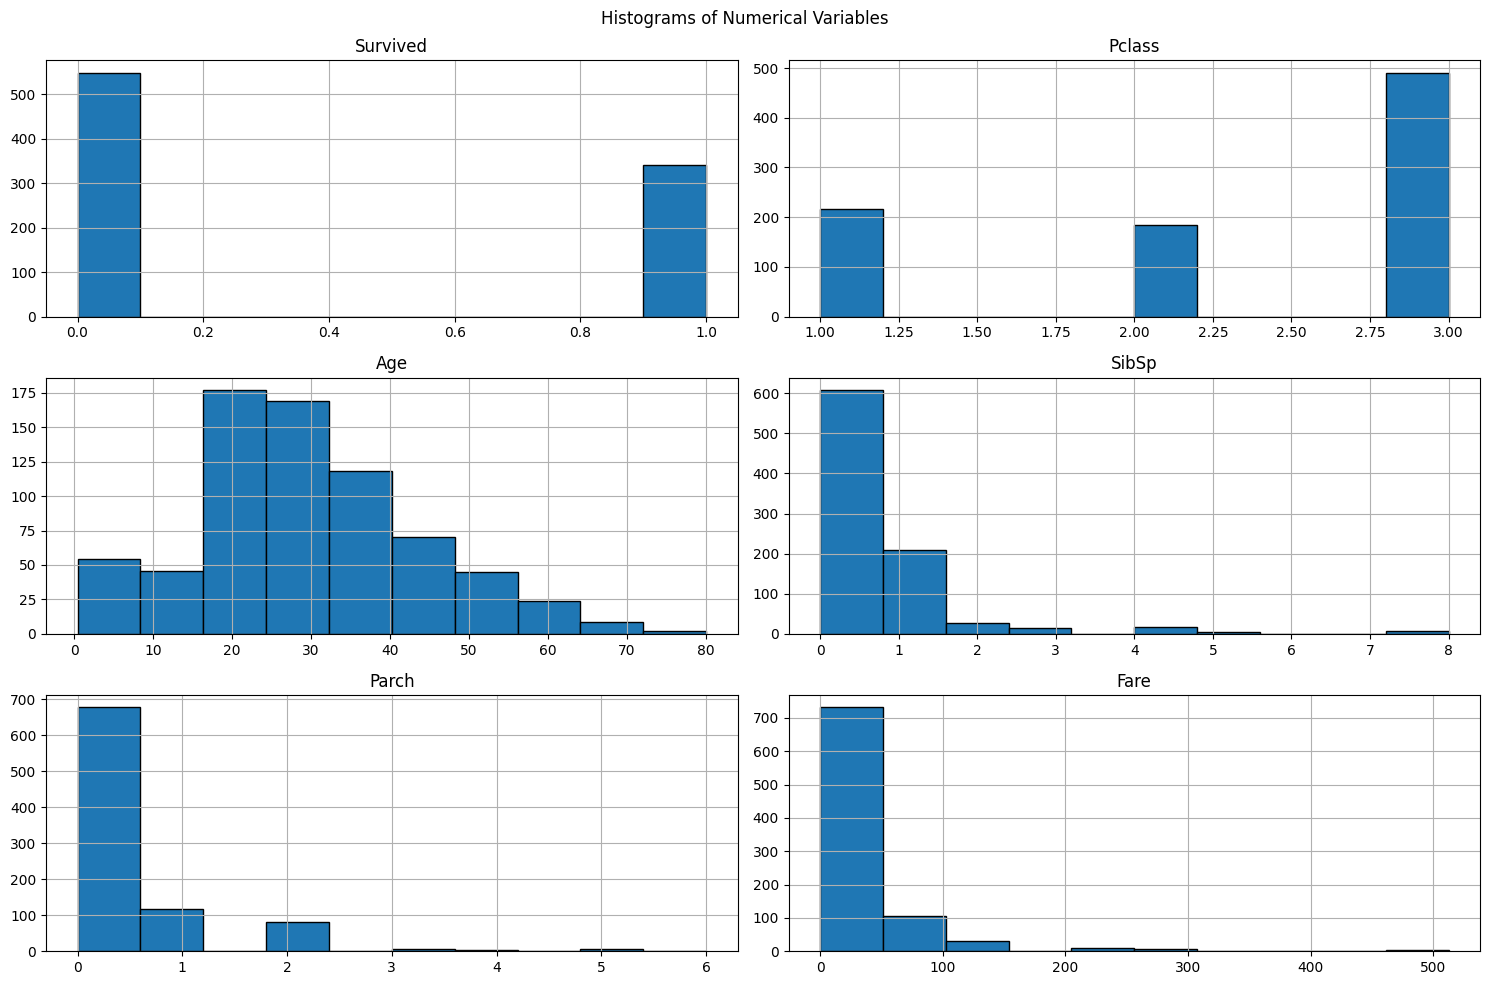

Survived    0.48
Pclass     -0.63
Age         0.39
SibSp       3.70
Parch       2.75
Fare        4.79
dtype: float64


In [6]:
numeric_df.hist(figsize=(15, 10), bins=10, edgecolor="black")
plt.suptitle("Histograms of Numerical Variables")
plt.tight_layout(); plt.show()

# Skewness numbers (useful for viva)
print(numeric_df.skew().round(2))

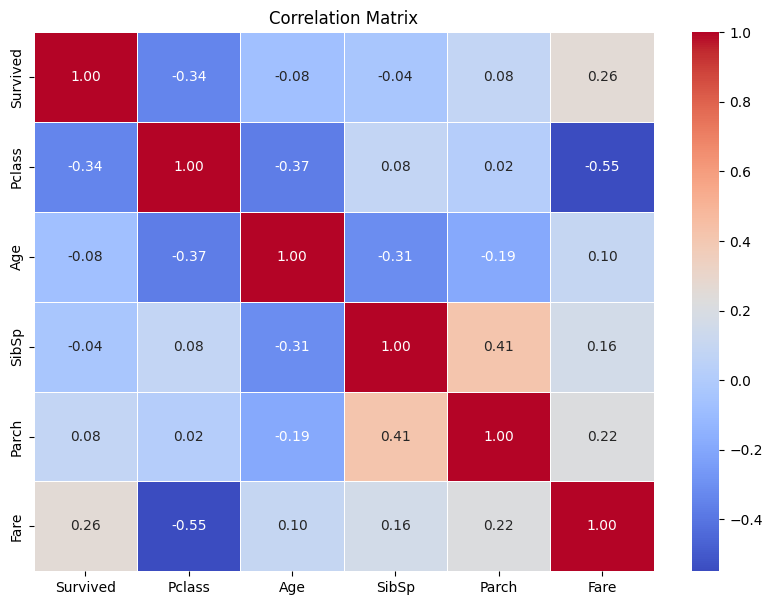

In [9]:
corr = numeric_df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix"); plt.show()

In [8]:
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack()
pairs.sort_values(key=abs, ascending=False).head(10)

Pclass    Fare     -0.549500
SibSp     Parch     0.414838
Pclass    Age      -0.369226
Survived  Pclass   -0.338481
Age       SibSp    -0.308247
Survived  Fare      0.257307
Parch     Fare      0.216225
Age       Parch    -0.189119
SibSp     Fare      0.159651
Age       Fare      0.096067
dtype: float64